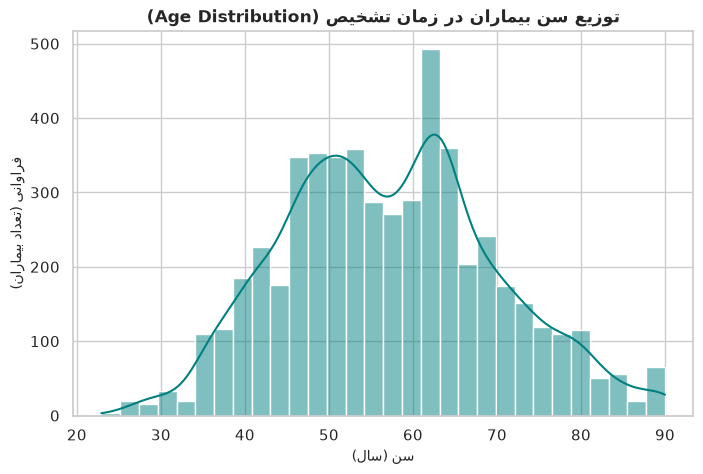

C:\Users\Mahdieh\AppData\Local\Temp\ipykernel_19172\3701787169.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=stage_counts.index, y=stage_counts.values, palette='Blues_d')


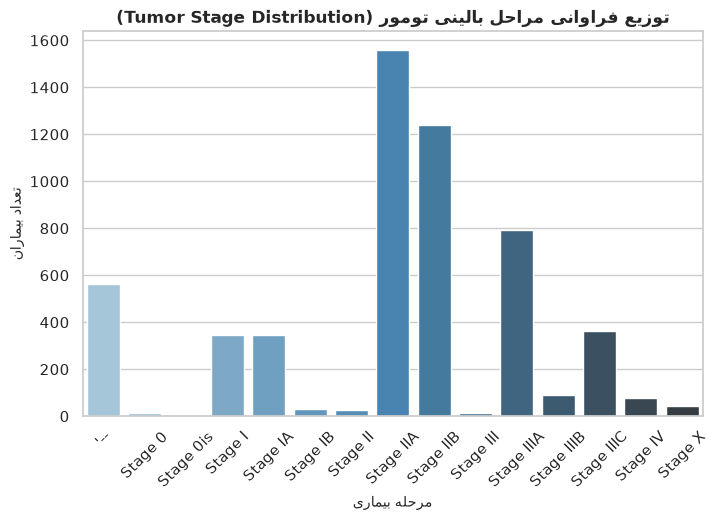

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# تنظیمات ظاهری نمودارها
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'DejaVu Sans' # سازگاری فونت

# بارگذاری داده‌های بالینی تمیزشده
clinical_df = pd.read_csv(r'E:\Uni\Statistics\Project\data\clinical.tsv', sep='\t', low_memory=False)

# ۱. نمودار هیستوگرام سن تشخیص (Age at Diagnosis)
plt.figure(figsize=(8, 5))
# فرض بر این است که ستون سن در فایل بالینی وجود دارد؛ در غیر این صورت نام ستون را تطبیق دهید
age_col = [c for c in clinical_df.columns if 'age' in c.lower() and ('diagnos' in c.lower() or 'at_dx' in c.lower())]
if age_col:
    # تبدیل سن به سال (اگر بر حسب روز باشد)
    ages = pd.to_numeric(clinical_df[age_col[0]], errors='coerce')
    if ages.max() > 150: # یعنی احتمالاً بر حسب روز است
        ages = ages / 365.25
        
    sns.histplot(ages.dropna(), kde=True, color='teal', bins=30)
    plt.title('توزیع سن بیماران در زمان تشخیص (Age Distribution)', fontsize=12, fontweight='bold')
    plt.xlabel('سن (سال)', fontsize=10)
    plt.ylabel('فراوانی (تعداد بیماران)', fontsize=10)
    plt.savefig(r'E:\Uni\Statistics\Project\figures\age_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()

# ۲. نمودار میله‌ای مرحله بالینی تومور (Tumor Stage)
stage_col = [c for c in clinical_df.columns if 'stage' in c.lower() and ('pathologic' in c.lower() or 'overall' in c.lower())]
if stage_col:
    plt.figure(figsize=(8, 5))
    stage_counts = clinical_df[stage_col[0]].value_counts().sort_index()
    sns.barplot(x=stage_counts.index, y=stage_counts.values, palette='Blues_d')
    plt.title('توزیع فراوانی مراحل بالینی تومور (Tumor Stage Distribution)', fontsize=12, fontweight='bold')
    plt.xlabel('مرحله بیماری', fontsize=10)
    plt.ylabel('تعداد بیماران', fontsize=10)
    plt.xticks(rotation=45)
    plt.savefig(r'E:\Uni\Statistics\Project\figures\tumor_stage_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()